**Aim:** anlysis of scRNA-seq data

**Tools**: 
1. Preprocessing: [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
2. Normalization/denoising/imputation of expression: [`scvi`](https://docs.scvi-tools.org/en/stable/user_guide/models/scvi.html)

# 1. Preprocessing

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [4]:
results_file = 'preprocessing/adata-cleaned.h5ad.gz'

adata0 = sc.read_h5ad(results_file)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.


### Prepare data 

https://docs.scvi-tools.org/

In [21]:
adata = adata0.copy()

Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [22]:
adata.layers["counts"] = adata.X.copy() # preserve counts
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata # freeze the state in `.raw`

In [25]:
sc.pp.highly_variable_genes(
    adata, #min_mean=0.0125, max_mean=3, min_disp=0.5,
    n_top_genes=1200,
    subset=True,
    layer="counts",
    flavor="cell_ranger",
    batch_key="batch"
)


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [26]:
adata

AnnData object with n_obs × n_vars = 22478 × 1203
    obs: 'batch', 'cond', 'group'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg'
    layers: 'counts'

In [29]:
scvi.data.setup_anndata(
    adata,
    layer="counts",
    categorical_covariate_keys=["batch", "group"],
    # continuous_covariate_keys=["percent_mito", "percent_ribo"]
)


INFO     No batch_key inputted, assuming all cells are same batch                            
INFO     No label_key inputted, assuming all cells have same label                           
INFO     Using data from adata.layers["counts"]                                              
INFO     Computing library size prior per batch                                              
INFO     Successfully registered anndata object containing 22478 cells, 1203 vars, 1 batches,
         1 labels, and 0 proteins. Also registered 2 extra categorical covariates and 0 extra
         continuous covariates.                                                              
INFO     Please do not further modify adata until model is trained.                          


In [30]:
model = scvi.model.SCVI(adata)

In [31]:
model

SCVI Model with the following params: 
n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, 
gene_likelihood: zinb, latent_distribution: normal
Training status: Not Trained

To print summary of associated AnnData, use: scvi.data.view_anndata_setup(model.adata)

In [32]:
model.train()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores


Epoch 356/356: 100%|██████████| 356/356 [29:58<00:00,  5.05s/it, loss=624, v_num=1]


In [33]:
model.save("preprocessing/scvi_model/")

In [ ]:
# model = scvi.model.SCVI.load("my_model/", adata=adata, use_gpu=False)

### Obtaining model outputs


In [34]:
latent = model.get_latent_representation()

It’s often useful to store the outputs of scvi-tools back into the original anndata, as it permits interoperability with Scanpy.


In [35]:
adata.obsm["X_scVI"] = latent

In [36]:
adata.layers["scvi_normalized"] = model.get_normalized_expression(
    library_size=10e4
)

In [37]:
adata

AnnData object with n_obs × n_vars = 22478 × 1203
    obs: 'batch', 'cond', 'group', '_scvi_batch', '_scvi_labels', '_scvi_local_l_mean', '_scvi_local_l_var'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', '_scvi'
    obsm: '_scvi_extra_categoricals', 'X_scVI'
    layers: 'counts', 'scvi_normalized'

In [38]:
results_file = 'preprocessing/adata-denoised.h5ad.gz'

adata.write_h5ad(results_file)

### Plot training epochs ...

In [43]:
model.history.keys()

dict_keys(['train_loss_step', 'train_loss_epoch', 'elbo_train', 'reconstruction_loss_train', 'kl_local_train', 'kl_global_train'])

In [51]:
# fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(3,3),dpi=300)
# x = 141

# ax.plot(model.history["elbo_train"], label="elbo_train")
# ax.plot(model.history["train_loss_epoch"], label="train_loss_epoch")
# # axes[i].set_ylim(9000, 15000)
# ax.legend()

# fig.tight_layout()
# # fig.savefig('figures/totalVI_training.pdf')

### Explore

raw counts

In [52]:
# run PCA then generate UMAP plots
sc.tl.pca(adata)
sc.pp.neighbors(adata, n_pcs=30, n_neighbors=20)
sc.tl.umap(adata, min_dist=0.3)

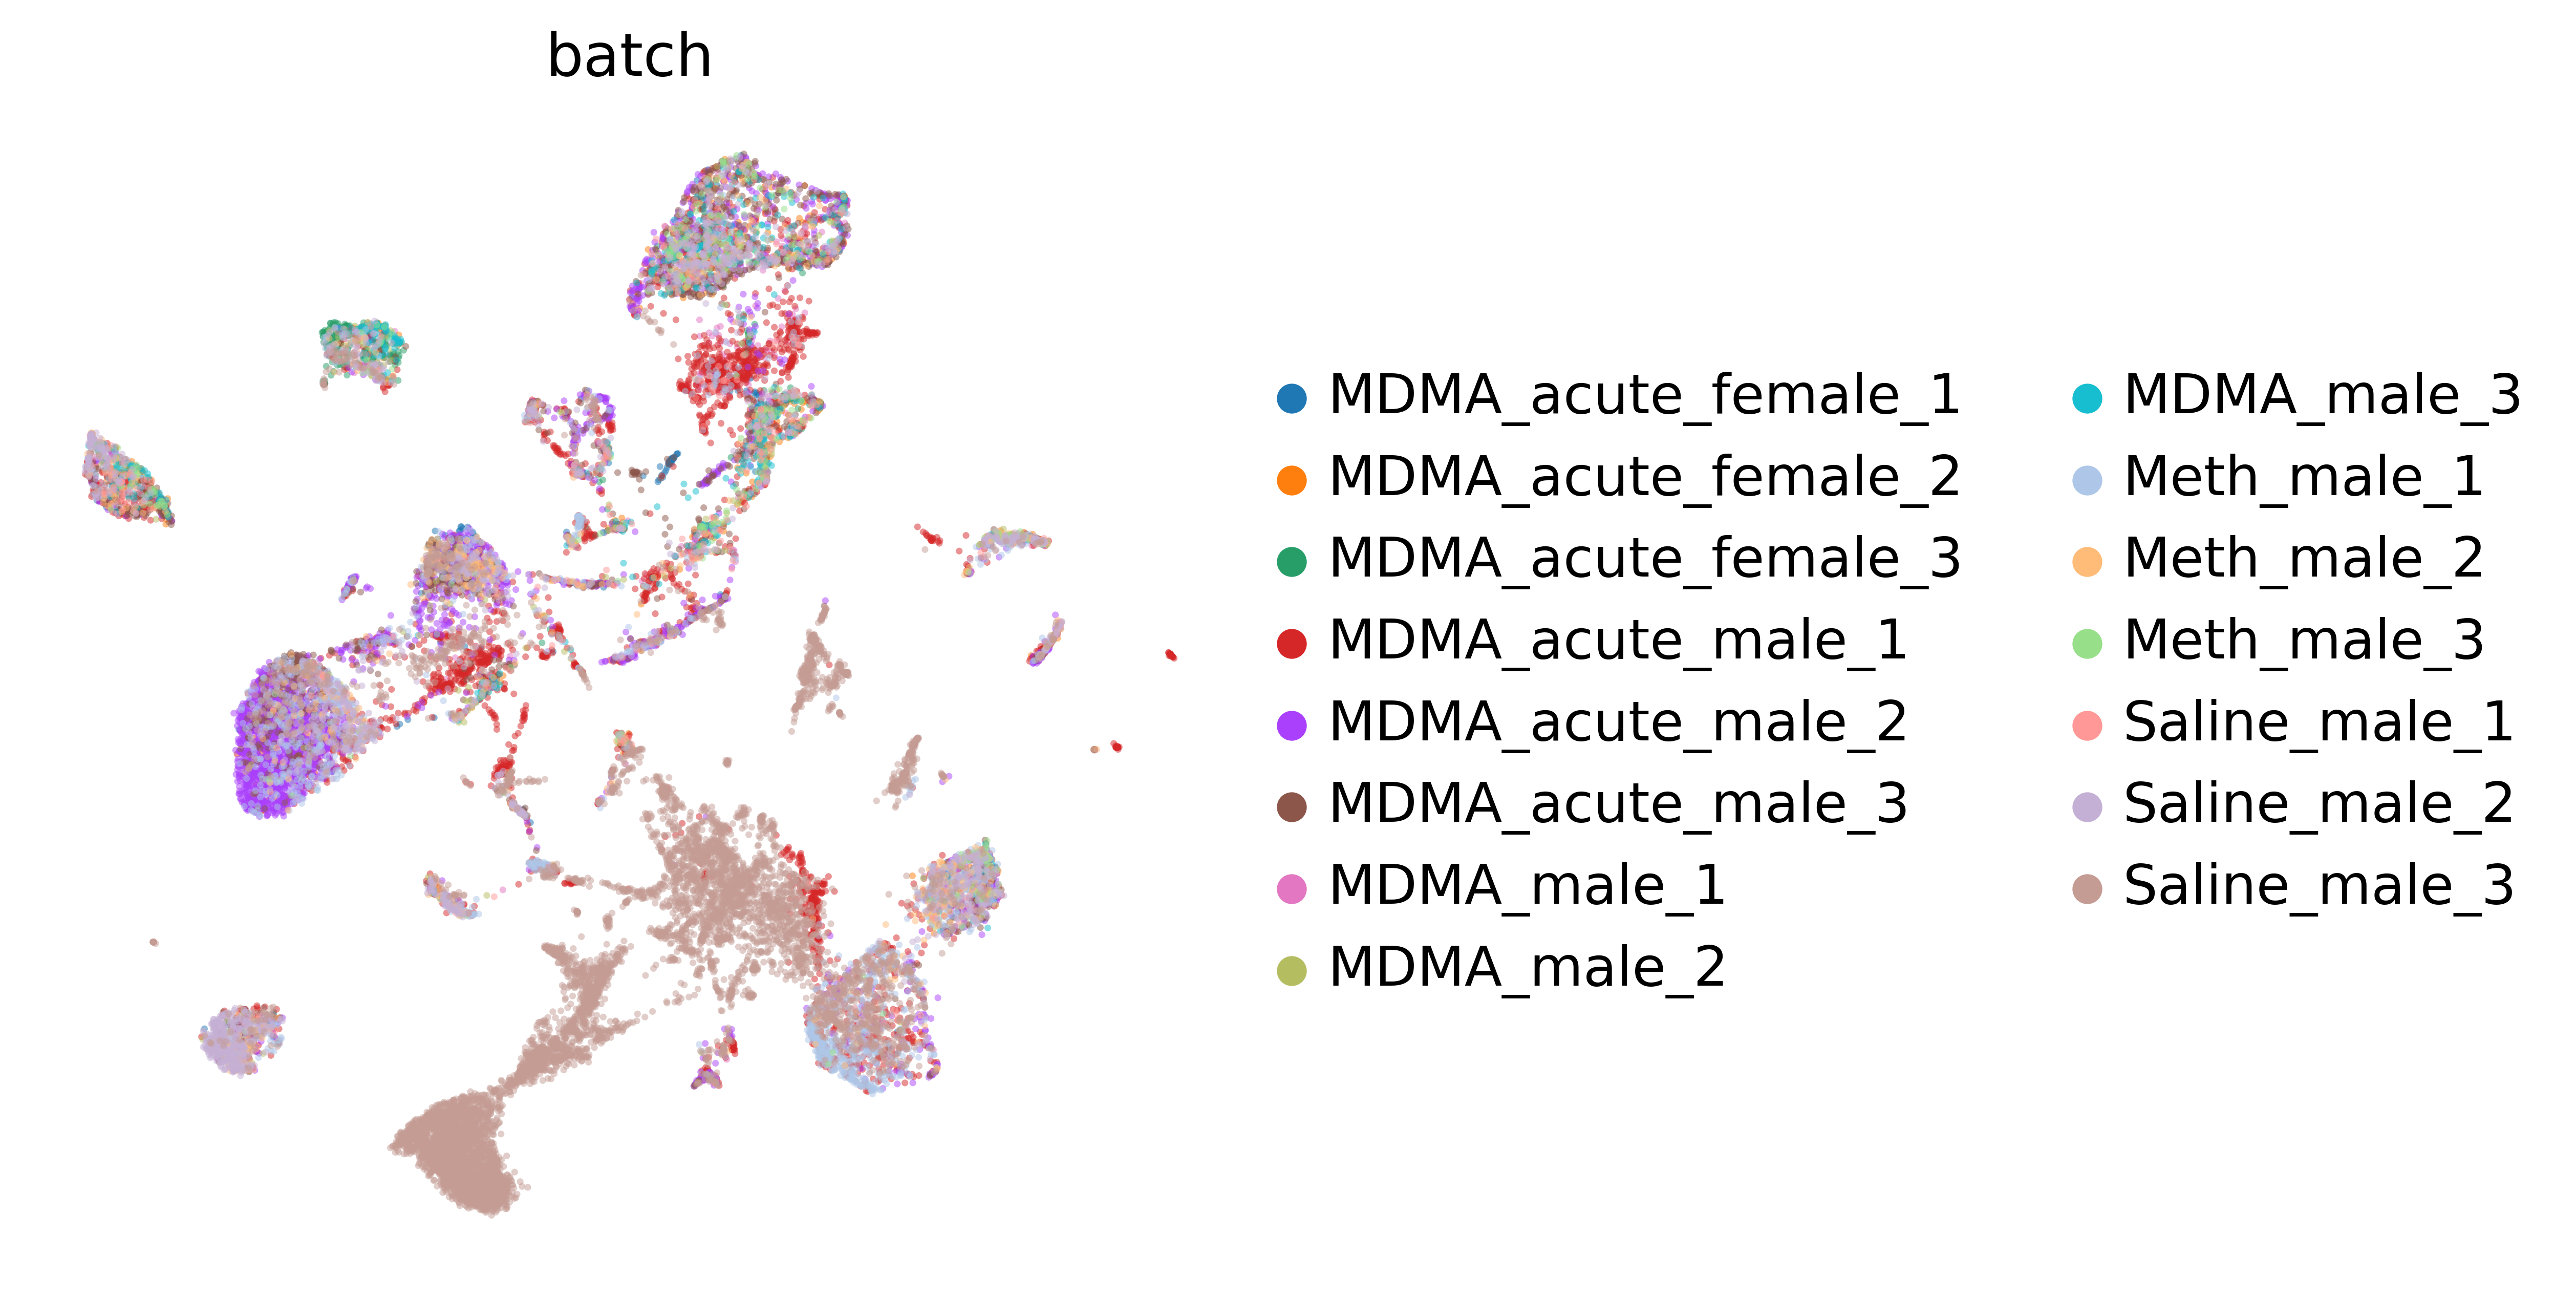

In [55]:
sc.pl.umap(
    adata,
    color=["batch"],
    frameon=False,alpha=0.5,size=10
)

scvi counts

In [68]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.umap(adata, min_dist=0.2)

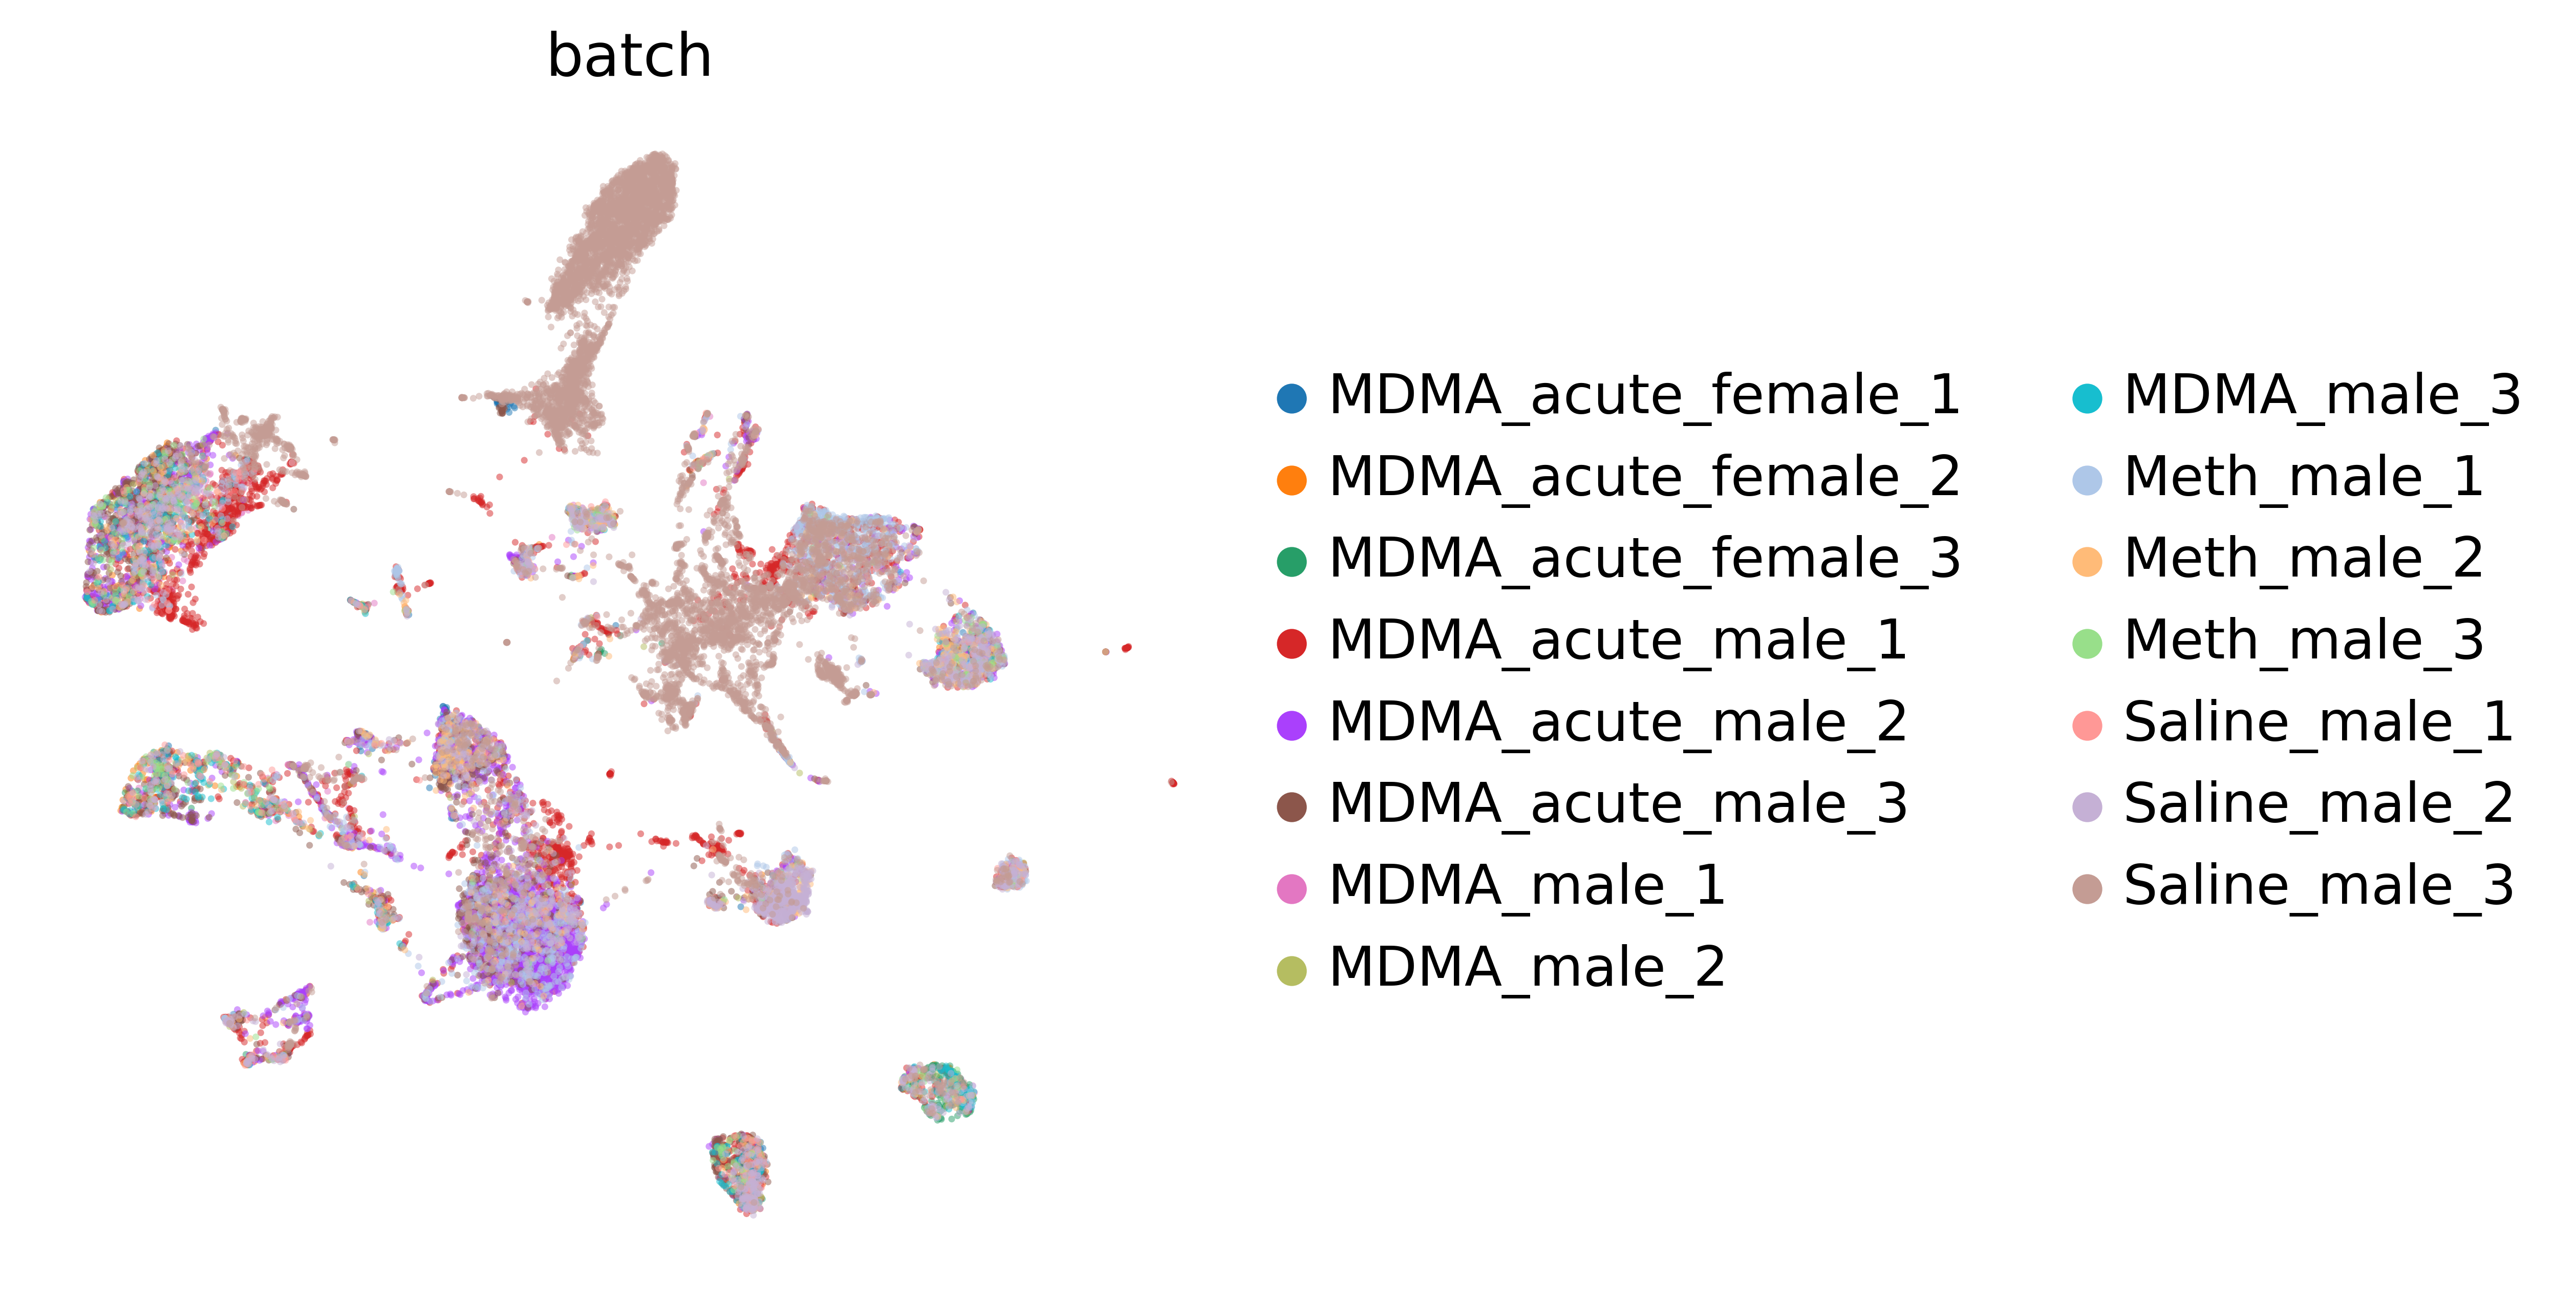

In [69]:
sc.pl.umap(
    adata,
    color=["batch"],
    frameon=False,alpha=0.5,size=10
)

In [88]:
# neighbors were already computed using scVI
sc.tl.leiden(adata, key_added="leiden_scVI", resolution=0.2)

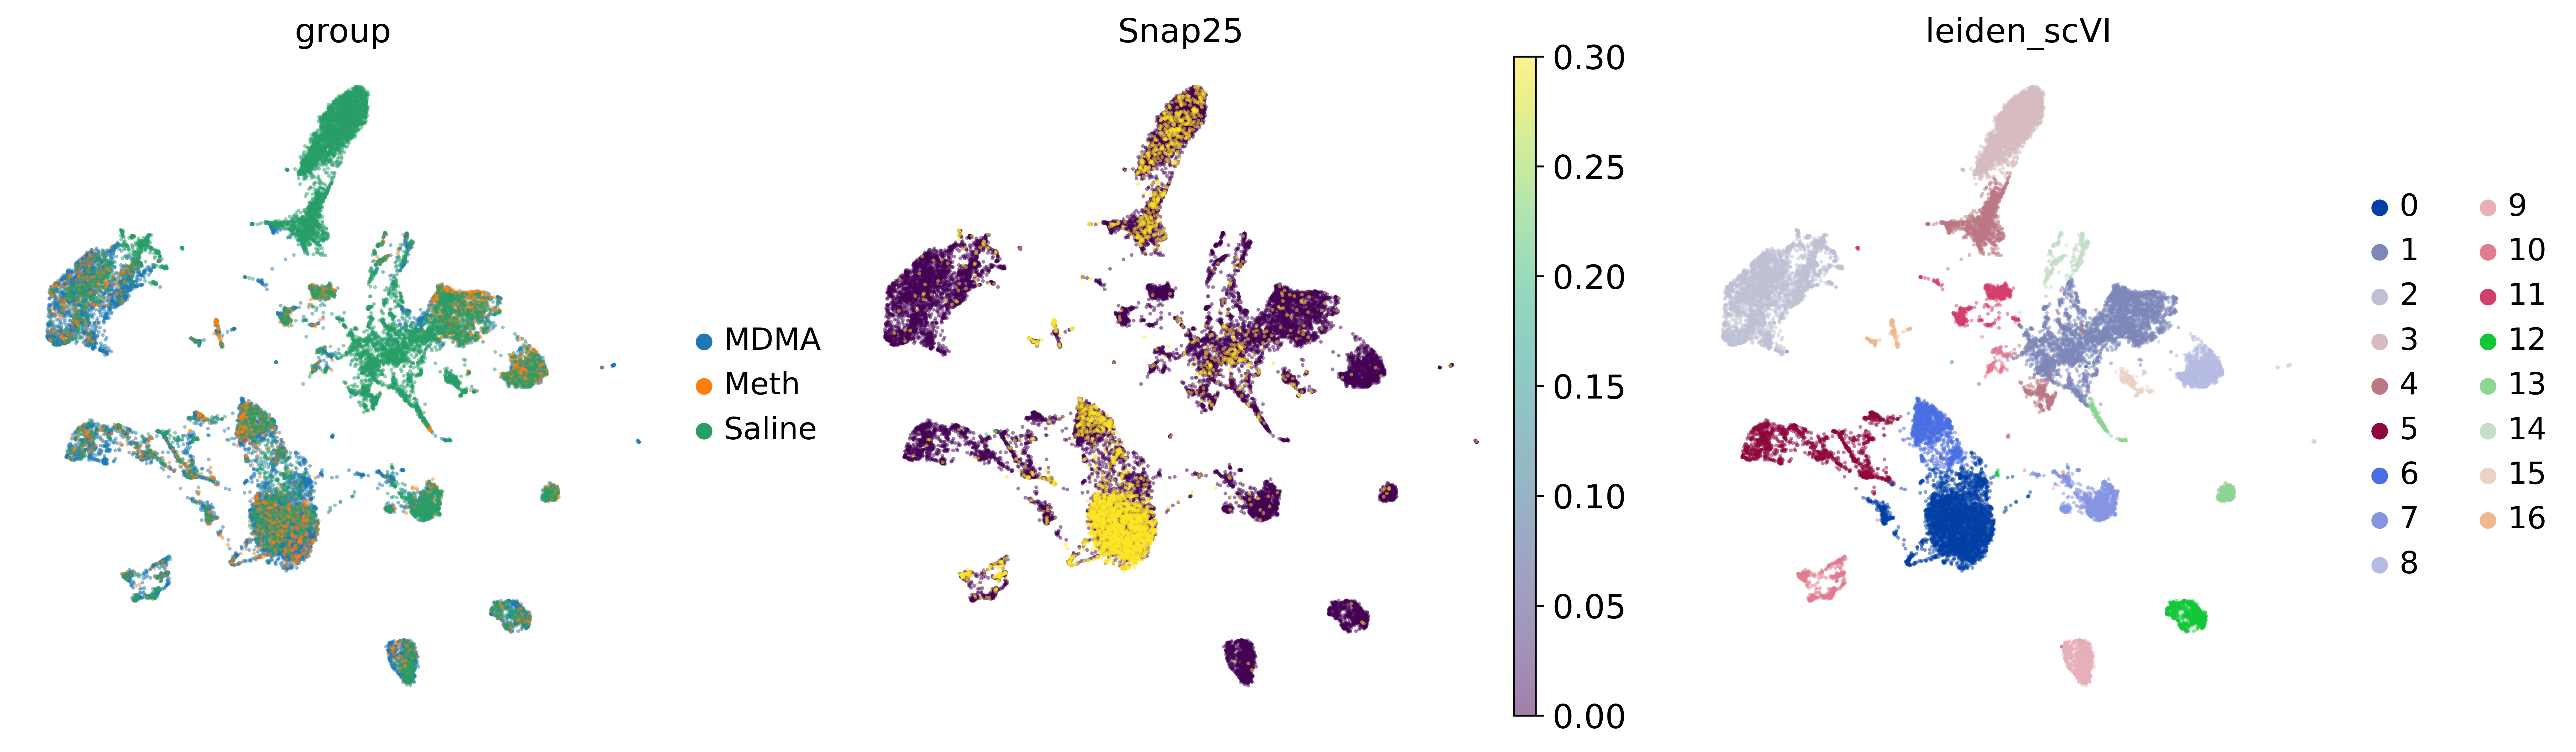

In [89]:
sc.pl.umap(
    adata,
    color=['group','Snap25',"leiden_scVI"],
    vmax=0.3,
    vmin=0,
    frameon=False,alpha=0.5,size=10
)

In [90]:
results_file = 'celltyping/adata-denoised-clustered.h5ad.gz'

adata.write_h5ad(results_file)

### Label Snap25+/-
Divide cells into `Snap25+` and `Snap25-` populations

In [91]:
def mark_Snap25(adata,Snap25_thr = 0):

    adata.obs['marker'] = ''
    adata.obs.loc[adata.to_df().loc[:,'Snap25'] <= Snap25_thr, 'marker'] = 'Snap25-'
    adata.obs.loc[adata.to_df().loc[:,'Snap25'] > Snap25_thr, 'marker'] = 'Snap25+'

In [92]:
mark_Snap25(adata)

In [151]:
df0 = pd.concat([
    adata.obs.groupby(['marker','leiden_scVI']).size()['Snap25+'],
    adata.obs.groupby(['marker','leiden_scVI']).size()['Snap25-']
],axis=1).rename(columns={0:'Snap25+',1:'Snap25-'})

df= df0.copy()
df['Snap25+'] = df0['Snap25+'] / df0.sum(axis=1) * 100
df['Snap25-'] = df0['Snap25-'] / df0.sum(axis=1) * 100
df = df.sort_values('Snap25+',ascending=False)

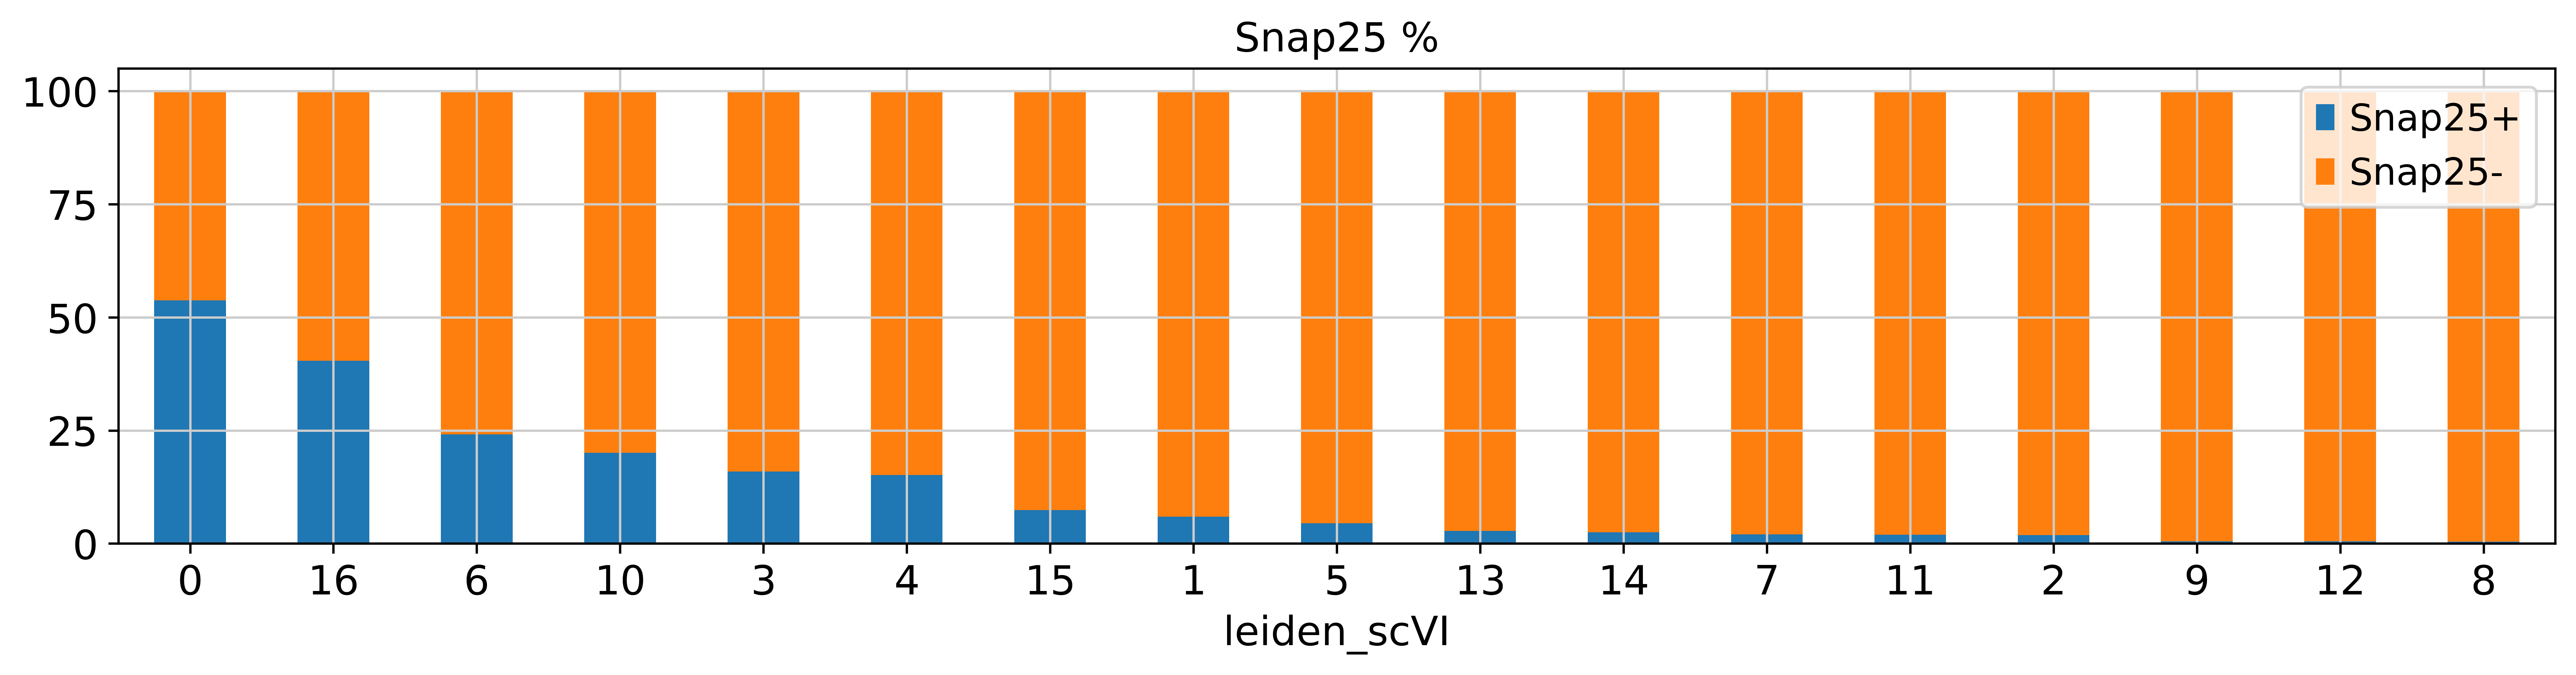

In [175]:
ax = df.plot.bar(stacked=True,rot=0,figsize=(15,3))
ax.set_title('Snap25 %')
plt.savefig('celltyping/Snap25_percent_clust_denoised.pdf')
# show plot
plt.show()

In [81]:
!date

Thu Aug 11 19:38:15 PDT 2022
